# Семинар. Стационарное тепловое состояние поршня: осесимметричный метод конечных элементов

**Тема:** расчёт стационарного температурного поля поршня ДВС в осесимметричной постановке с использованием линейных треугольных конечных элементов и языка Python.

**Цель семинара:** применить алгоритм, изученный при расчёте теплового состояния пластины, к реальной геометрии детали двигателя и показать, как изменяются элементные матрицы и граничные интегралы при переходе к осесимметричной задаче.

В ходе занятия мы последовательно:

1. Сформулируем физическую и математическую постановку задачи.
2. Загрузим подготовленные массивы сетки поршня с размеченными физическими границами.
3. Выведем элементную матрицу теплопроводности в координатах $(r,z)$.
4. Соберём глобальную матрицу и используем заранее размеченные участки границы.
5. Зададим конвективный теплообмен с газом, маслом и сопряжёнными деталями.
6. Решим систему уравнений и проанализируем полученное поле температур.

**Связь с предыдущим семинаром:** аппроксимация линейным треугольником, функции формы, вариационный принцип и сборка глобальной матрицы остаются прежними. Главное отличие — **вес $2\pi r$**, учитывающий вращение меридионального сечения вокруг оси.

**Видеоматериалы:** [видео 1](https://www.youtube.com/watch?v=YxowmVx28yU), [видео 2](https://www.youtube.com/watch?v=Kk2t4AOI5xM), [видео 3](https://www.youtube.com/watch?v=wIt4JFuWPGs).


## Библиотеки и пути к файлам

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve
from pathlib import Path
## для импорта словаря
import json

In [2]:
# Сгенерированная сетка и массивы для основного расчёта.
mesh_dir = Path("_mesh")

## 1. Физическая постановка задачи

Рассматриваем осесимметричное тело — поршень двигателя внутреннего сгорания. Его трёхмерная геометрия представляется вращением меридионального сечения вокруг оси $z$.

Предполагаем:

- стационарный процесс теплопроводности;
- однородный изотропный материал с постоянной теплопроводностью $\lambda$;
- отсутствие внутренних источников теплоты;
- независимость температуры от угла поворота: $\partial T/\partial\varphi=0$;
- тепловое взаимодействие отдельных участков поверхности с окружающими средами по закону Ньютона — Рихмана.

В цилиндрических координатах уравнение теплопроводности имеет вид:

$$
\boxed{
\frac{1}{r}\frac{\partial}{\partial r}
\left(r\lambda\frac{\partial T}{\partial r}\right)
+
\frac{\partial}{\partial z}
\left(\lambda\frac{\partial T}{\partial z}\right)=0.
}
$$

На участках конвективного теплообмена задаём:

$$
-\lambda\frac{\partial T}{\partial n}=\alpha(T-T_\infty),
$$

где $n$ — внешняя нормаль к меридиональному контуру, $\alpha$ — коэффициент теплоотдачи, $T_\infty$ — температура соответствующей среды. Положительный поток $q_{\mathrm{out}}=\alpha(T-T_\infty)$ направлен **из поршня**. Если отдельно задаётся поток *в тело*, используем принятое в предыдущем семинаре соглашение $q_{\mathrm{in}}>0$.

На оси вращения $r=0$ выполняется условие регулярности температурного поля: $\partial T/\partial r=0$. На остальных участках, где теплообмен не задан, принимается теплоизоляция.

## 2. Подготовленная сетка и граничные зоны

В отдельном подготовительном ноутбуке мы импортировали CAD-геометрию с Physical Groups, построили сетку в Gmsh и получили массивы `pnts`, `elms` и `boundary`.

В этом семинаре **не будем заново генерировать сетку**: загрузим результаты из файлов `nodes.csv`, `elements.csv`, `boundary.json`. Это позволяет сосредоточиться на физической постановке, выводе элементных матриц и сборке системы МКЭ.

Массив `pnts` содержит координаты $(r,z)$ в метрах, `elms` — индексы вершин треугольников, `boundary[name]['edges']` — пары индексов узлов граничных рёбер, `boundary[name]['length']` — длины рёбер. Все индексы уже согласованы с `pnts` и начинаются с нуля.

In [3]:
km = 45.0  # Теплопроводность, Вт/(м·К)

In [4]:
pnts = np.loadtxt(
    mesh_dir / "nodes.csv",
    delimiter=",", skiprows=1, ndmin=2)

elms = np.loadtxt(
    mesh_dir / "elements.csv",
    delimiter=",", skiprows=1, dtype=int, ndmin=2)

with open(mesh_dir / "boundary.json", encoding="utf-8") as f:
    boundary = json.load(f)

In [5]:
# сохраним количество элементов, чтобы потом можно было писать циклы по ним
nn = len(pnts)
ne = len(elms) 

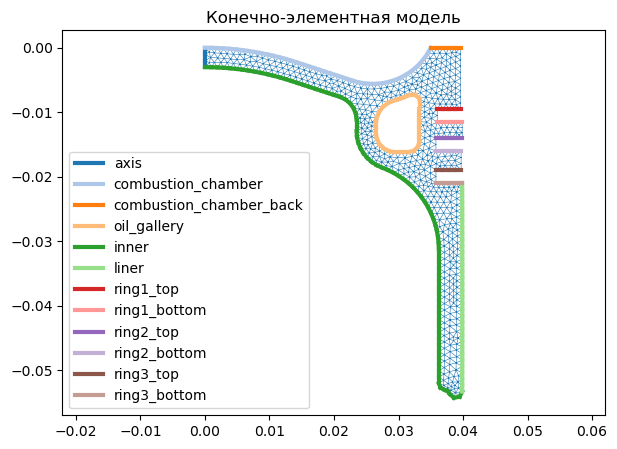

In [6]:
# Отображение всех физических групп
colors = plt.get_cmap("tab20").colors
# картинка
fig, ax = plt.subplots(figsize=(7,5))
plt.title('Конечно-элементная модель')
ax.triplot(pnts[:,0]  , pnts[:,1]  , elms, linewidth=0.4)
for i, bc in enumerate(boundary):
    edges = boundary[bc]['edges']
    plt.plot(pnts[edges, 0].T, pnts[edges, 1].T, color=colors[i], lw=3)
    plt.plot([], [], color=colors[i], lw=3, label=bc)
plt.axis('equal')
plt.legend(loc='lower left')
plt.show()

## 3. Элементная матрица теплопроводности осесимметричного треугольника

Как и для пластины, внутри линейного треугольного элемента температуру аппроксимируем через её значения в трёх узлах:

$$
T(r,z)=N_i(r,z)T_i+N_j(r,z)T_j+N_m(r,z)T_m.
$$

Функции формы линейны, поэтому производные температуры по координатам $r,z$ постоянны внутри элемента:

$$
\begin{pmatrix}
\partial T/\partial r\\[2pt]
\partial T/\partial z
\end{pmatrix}
=\frac{1}{\Delta_e}
\underbrace{\begin{pmatrix}
b_i&b_j&b_m\\
c_i&c_j&c_m
\end{pmatrix}}_{\mathbf H}
\begin{pmatrix}T_i\\T_j\\T_m\end{pmatrix},
$$

где $\Delta_e$ — **ориентированный** определитель координат, а площадь элемента равна $A_e=|\Delta_e|/2$.

Коэффициенты функций формы вычисляются по координатам вершин $(r_i,z_i)$, $(r_j,z_j)$, $(r_m,z_m)$:

$$
\begin{aligned}
\mathbf b&=(z_j-z_m,\ z_m-z_i,\ z_i-z_j),\\
\mathbf c&=(r_m-r_j,\ r_i-r_m,\ r_j-r_i).
\end{aligned}
$$

### Почему в осесимметричной задаче появляется радиус?

В плоской задаче пластины объём элементарной области равен $dV=t\,dA$, где $t$ — толщина. Здесь при вращении элемента вокруг оси симметрии:

$$
\boxed{dV=2\pi r\,dA.}
$$

Поэтому вклад теплопроводности в функционал равен:

$$
\Phi_{e}^{(\lambda)}
=\frac{\lambda}{2}\int_{V_e}|\nabla T|^2\,dV
=\pi\lambda\int_{A_e}r\left[
\left(\frac{\partial T}{\partial r}\right)^2+
\left(\frac{\partial T}{\partial z}\right)^2\right]dA.
$$

Поскольку $\nabla T$ постоянно внутри линейного элемента, а $r$ является линейной координатой, интеграл от радиуса вычисляется точно:

$$
\int_{A_e}r\,dA=A_e\bar r_e,\qquad
\bar r_e=\frac{r_i+r_j+r_m}{3}.
$$

Следовательно:

$$
\Phi_e^{(\lambda)}=\frac12\{T\}_e^{\mathsf T}\mathbf K_e\{T\}_e,
$$

$$
\boxed{\mathbf K_e=\frac{\pi\lambda\bar r_e}{2A_e}\,\mathbf H^{\mathsf T}\mathbf H.}
$$

**Сравнение с пластиной:** там коэффициент перед $\mathbf H^{\mathsf T}\mathbf H$ был $\lambda t/(4A_e)$; здесь вместо постоянной толщины учитывается окружность $2\pi r$.

Физический смысл $\bar r_e$: при одинаковой форме и площади элементы, расположенные дальше от оси, представляют больший объём материала.

### Условие стационарности функционала

Как и в предыдущем семинаре, **матрица и вектор МКЭ получаются из условия стационарности функционала по неизвестным узловым температурам**.

После подстановки функций формы и сборки всех объёмных и граничных вкладов полный функционал представляет собой квадратичную функцию узловых температур:

$$
\Phi(\mathbf T)=\frac12\mathbf T^{\mathsf T}\mathbf K\mathbf T-\mathbf T^{\mathsf T}\mathbf F+C.
$$

Здесь $\mathbf K$ состоит из объёмных матриц теплопроводности и граничных матриц конвекции, $\mathbf F$ — из векторов граничных тепловых нагрузок, а $C$ не зависит от неизвестных температур.

Поэтому:

$$
\frac{\partial\Phi}{\partial\mathbf T}=\mathbf K\mathbf T-\mathbf F=\mathbf 0,
$$

откуда получаем систему:

$$
\boxed{\mathbf K\mathbf T=\mathbf F.}
$$

Константа $C$ не влияет на систему уравнений, поскольку её производные по узловым температурам равны нулю. В нашей задаче на поршне нет фиксированных температур: все заданные теплообменные условия относятся к III роду.


In [7]:
# Обозначим функцию для создания локальных(элементных) матриц теплопроводности
def get_kel(element, km):
    i , j , m = element
    ri, zi = pnts[i]
    rj, zj = pnts[j]
    rm, zm = pnts[m]
    r_avg = (ri + rj + rm) / 3.0
    area = 0.5 * abs((rj-ri)*(zm-zi) - (zj-zi)*(rm-ri))
    b = np.array([zj-zm, zm-zi, zi-zj])
    c = np.array([rm-rj, ri-rm, rj-ri])
    H = np.array([b, c])
    Kel = np.pi * km * r_avg / (2 * area) * (H.T @ H)                     # используем не поэлементное умножение, а матричное
    return Kel   

### Проверка элементной матрицы

Если во всех узлах элемента задать одинаковую температуру $T_i=T_j=T_m$, градиент температуры будет равен нулю. Поэтому:

$$
\mathbf K_e\begin{pmatrix}1\\1\\1\end{pmatrix}=\mathbf 0.
$$

Элементная матрица должна быть симметричной и положительно полуопределённой. Суммы её строк равны нулю с точностью до ошибок вычислений.

In [8]:
Ke0 = get_kel(elms[0], km = km)
print('Матрица одного элемента:\n', Ke0)
print('Симметрична:', np.allclose(Ke0, Ke0.T))
print('Суммы строк (должны быть близки к 0):', Ke0.sum(axis=1))

Матрица одного элемента:
 [[ 4.52147813 -2.49909503 -2.0223831 ]
 [-2.49909503  6.60072842 -4.10163339]
 [-2.0223831  -4.10163339  6.12401649]]
Симметрична: True
Суммы строк (должны быть близки к 0): [0.0000000e+00 0.0000000e+00 8.8817842e-16]


## 4. Сборка глобальной матрицы

Каждый треугольник имеет три глобальных индекса узлов, хранящихся в строке массива `elms`. Полученная матрица $\mathbf K_e$ добавляется к соответствующим девяти позициям глобальной матрицы.

Как и ранее:

$$
\mathbf K_{\mathrm{glob}}\mathbf T=\mathbf F_{\mathrm{glob}}.
$$
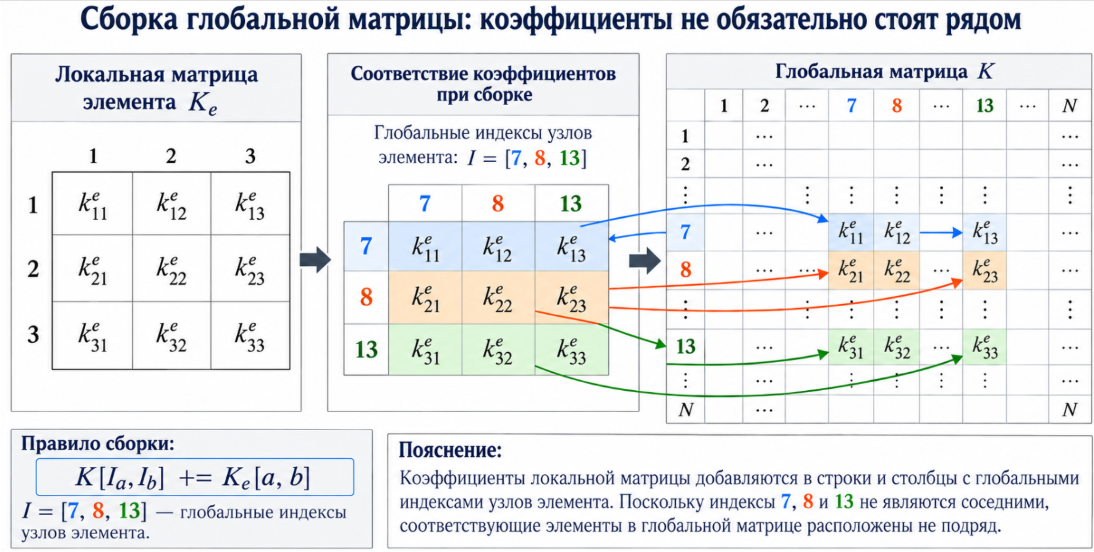

In [9]:
Kglob  = np.zeros([nn, nn])
Fglob = np.zeros(nn)

In [10]:
# чтобы сформировать подмассив по выбранным индексам нужно использовать np.ix_
for el in range(ne):
    IndX =elms[el]
    IndXArr = np.ix_(IndX, IndX)
    Kglob[IndXArr] += get_kel(elms[el], km = km)    

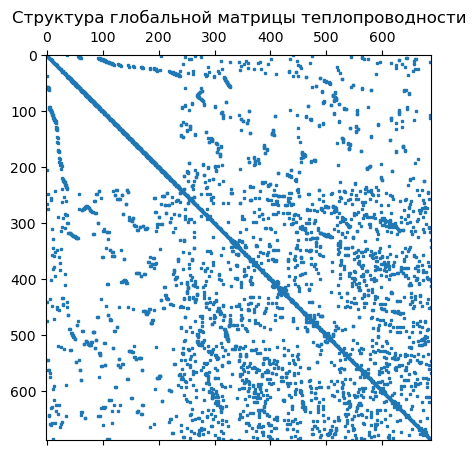

In [11]:
plt.figure(figsize=(5, 5))
plt.spy(Kglob, markersize=2)
plt.title('Структура глобальной матрицы теплопроводности')
plt.show()

## 5. Граничные участки поршня

В предыдущем семинаре по пластине границы определяли по координатам. В настоящем расчёте их уже разметили как `Physical Groups` в Gmsh и сохранили в словарь `boundary`.

Для конвективного теплообмена достаточно знать пары узлов на каждом граничном ребре и их длины. На графике ниже проверим расположение зон. Неразмеченные участки по умолчанию считаем теплоизолированными.

### Граничный вклад в функционал

Для осесимметричной задачи поверхность, полученная вращением граничного ребра $\Gamma_e$, имеет элемент площади:

$$dS=2\pi r\,dL.$$

Поэтому вклад конвекции в функционал:

$$
\Phi_{\Gamma,e}^{(\alpha)}
=\frac12\int_{S_{\Gamma,e}}\alpha(T-T_\infty)^2\,dS
=\pi\alpha\int_{\Gamma_e}r(T-T_\infty)^2\,dL.
$$

Температура и радиус на ребре линейно зависят от функций формы:

$$T=N_iT_i+N_jT_j,\qquad r=N_i r_i+N_jr_j.$$

Подставим их в функционал и, как в предыдущем семинаре, возьмём производные по $T_i,T_j$. В результате получим вклад вида:

$$
\frac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial\{T\}_\Gamma}
=\mathbf K_{\Gamma,e}\{T\}_\Gamma-\mathbf F_{\Gamma,e}.
$$

Для линейного ребра используются точные интегралы:

$$
\begin{aligned}
\int_{\Gamma_e}rN_i^2\,dL&=\frac{L}{12}(3r_i+r_j),\\
\int_{\Gamma_e}rN_iN_j\,dL&=\frac{L}{12}(r_i+r_j),\\
\int_{\Gamma_e}rN_j^2\,dL&=\frac{L}{12}(r_i+3r_j),\\
\int_{\Gamma_e}rN_i\,dL&=\frac{L}{6}(2r_i+r_j),\\
\int_{\Gamma_e}rN_j\,dL&=\frac{L}{6}(r_i+2r_j).
\end{aligned}
$$

Получаем **элементную матрицу конвективного теплообмена**:

$$
\boxed{
\mathbf K_{\Gamma,e}=
\frac{\pi\alpha L}{6}
\begin{pmatrix}
3r_i+r_j&r_i+r_j\\
r_i+r_j&r_i+3r_j
\end{pmatrix}
}
$$

и **элементный вектор тепловой нагрузки**:

$$
\boxed{
\mathbf F_{\Gamma,e}=
\frac{\pi\alpha T_\infty L}{3}
\begin{pmatrix}
2r_i+r_j\\
r_i+2r_j
\end{pmatrix}.
}
$$

В отличие от плоской задачи, нагрузка не обязана распределяться между узлами поровну: при $r_i\ne r_j$ окружности вращения узлов имеют разные радиусы. Формулы учитывают линейное изменение радиуса вдоль ребра **точно**, без приближения $r\approx\bar r$.

In [12]:
def bc3type(K, F, boundary, hinf, Tinf):
    edges = boundary['edges']
    L = boundary['length']
    for nds, length in zip(edges, L):
        ri, _ = pnts[nds[0]]
        rj, _ = pnts[nds[1]]
      
        F[nds] += np.pi * length * hinf *Tinf / 3 * np.array( [2*ri+rj,
                                                         ri+2*rj])
        IndXArr = np.ix_(nds, nds)
        K[IndXArr] += np.pi* hinf *  length / 6 * np.array([[3*ri+rj, ri+rj],
                                                     [ri+rj,   ri+3*rj]])
    return K, F 

| Участок | $T_\infty$, °C | $\alpha$, Вт/(м²·К) |
|---|---:|---:|
| Камера сгорания (`combustion_chamber`) | 700 | 650 |
| Камера сгорания (`combustion_chamber_back`) | 700 | 350 |
| Масляная галерея (`oil_gallery`) | 85 | 1750 |
| Внутренние поверхности (`inner`) | 85 | 250 |
| Наружная поверхность юбки (`liner`) | 135 | 3000 |
| Первая канавка — верх (`ring1_top`) | 185 | 600 |
| Первая канавка — низ (`ring1_bottom`) | 175 | 6000 |
| Вторая канавка — верх (`ring2_top`) | 165 | 180 |
| Вторая канавка — низ (`ring2_bottom`) | 160 | 4000 |
| Третья канавка — верх (`ring3_top`) | 150 | 750 |
| Третья канавка — низ (`ring3_bottom`) | 145 | 750 |

In [13]:
Kcalc = Kglob.copy()
Fcalc = Fglob.copy()
# Параметры конвекции :
# имя Physical Group -> (коэффициент теплоотдачи alpha, температура среды Tinf).
bc_params = {
    "combustion_chamber":      (650, 700),
    "combustion_chamber_back": (350, 700),
    "oil_gallery":             (1750, 85),
    "inner":                   (250, 85),
    "liner":                   (3000, 135),
    "ring1_top":               (600, 185),
    "ring1_bottom":            (6000, 175),
    "ring2_top":               (180, 165),
    "ring2_bottom":            (4000, 160),
    "ring3_top":               (750, 150),
    "ring3_bottom":            (750, 145),
}
for name, (alpha, Tinf) in bc_params.items():
    # boundary[name]['edges'] хранит индексы узлов в pnts.
    Kcalc, Fcalc = bc3type(Kcalc, Fcalc, boundary[name], alpha, Tinf)

In [14]:
T_sol = np.linalg.solve(Kcalc, Fcalc)

**Визуализация температурного поля**

Результат решения — массив `T_sol`, содержащий температуру в каждом узле расчётной сетки. В пределах элемента температура интерполируется линейными функциями формы. Отобразим поле температур в меридиональном сечении.


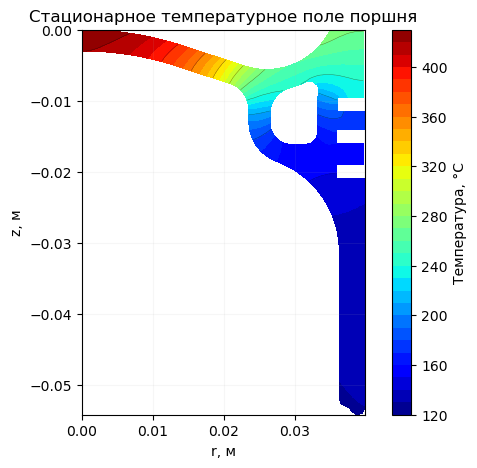

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
field = ax.tricontourf(pnts[:, 0], pnts[:, 1], elms, T_sol,
                       levels=30, cmap='jet')
ax.tricontour(pnts[:, 0], pnts[:, 1], elms, T_sol,
              levels=10, colors='black', linewidths=0.3, alpha=0.55)
plt.colorbar(field, ax=ax, label='Температура, °C')
ax.set(xlabel='r, м', ylabel='z, м', title='Стационарное температурное поле поршня')
ax.set_aspect('equal')
ax.grid(alpha=0.1)
plt.show()

## 6. Выводы по результатам семинара

В ходе семинара мы разработали Python-программу для расчёта стационарного температурного поля **поршня ДВС в осесимметричной постановке**.

Последовательно выполнены основные этапы конечно-элементного анализа: загрузка подготовленной меридиональной конечно-элементной сетки с размеченными Physical Groups, вывод элементной матрицы из вариационного функционала, сборка глобальной разреженной матрицы, идентификация участков теплообмена, решение СЛАУ и проверка энергетического баланса.

В сравнении с предыдущим семинаром по теплопроводности пластины **общий алгоритм МКЭ не изменился**. Главное математическое отличие — множитель $2\pi r$ в объёмных и поверхностных интегралах, учитывающий осевую симметрию детали. Именно он определяет вид матриц осесимметричного треугольного элемента и граничных рёбер.